# Сравнение робо-эдвайзера и доверительного управления
Мишарин Максим Максимович, РИМ-160950

## 1. Задача

В лекции 7 говорится, что робот позволяет снизить расходы на управление портфелем. Проверю это на примере робота ПСБ и ДУ ББР Брокера.

Начальная сумма 1 млн ₽, срок 10 лет, без пополнений. Валовая доходность 5%, 10% или 15% годовых, волатильность 10% или 20%. Основной вариант: ребалансировка раз в квартал с зачетом убытков. Дополнительно сравню ежемесячную и ежегодную ребалансировку, а также отказ от зачета.

## 2. Тарифы

Беру условия на **29.10.2026** и сохраняю их на все 10 лет.

| Комиссия | Робот ПСБ, «Инвестор» | ДУ ББР «Облигационная», сделки по «Успешному инвестору» |
|---|---|---|
| Управление | 0% | 1,5% годовых от средней стоимости активов |
| Покупка и продажа | 0,25% | 0,15%, минимум 0,10 ₽ |
| За успех | 0 | 0 |
| Обслуживание | 0 ₽ | 0 ₽ при стоимости каждого выпуска до 10 млн ₽ |
| Вывод рублей | 0 ₽ на счет в ПСБ | 0 ₽ на банковский счет в РФ |

Биржевой сбор включен в комиссию сделки. Отдельную плату за вход и выход не закладываю. При закрытии учитываю продажу бумаг, налог и начисленную плату за ДУ.

Источники:

- ПСБ: [робот-советник](https://www.psbank.ru/personal/wealth/robot-adviser), [тарифы](https://www.psbank.ru/personal/wealth/rates), [обслуживание и вывод](https://www.psbank.ru/personal/wealth/markets).
- ББР: [условия стандартного ДУ](https://bbrbroker.ru/products/doveritelnoe-upravlenie/), [договор и приложения](https://bbrbroker.ru/upload/medialibrary/821/c0f4nefqun8sxk7bzz10tlu76k0tp9kw.zip), приложение 8. Плата 1,5% рассчитывается ежеквартально. Вход в стандартные стратегии от 500 тыс. ₽, поэтому 1 млн ₽ достаточно.
- [Тариф ББР с 01.10.2026](https://bbrbroker.ru/upload/iblock/911/4yrntyuw46ysu8b828rpy2w268tac7w0.pdf), п. 2.1.1 и раздел 4. [Раздел действующих документов](https://bbrbroker.ru/about/disclosure/regulation/).

Выбрал тарифы с постоянной ставкой сделки и без ежемесячной платы при принятом размере позиций. У стратегии «Облигационная» нет комиссии за успех. Робот ПСБ бесплатный, но банк получает комиссию с каждой сделки.



## 3. Как устроена модель

- Считаю 3 000 случайных траекторий по 120 месяцев. Средняя годовая доходность и ее стандартное отклонение заданы условием. Для обоих вариантов использую одинаковые рыночные изменения и фиксированный seed.
- Портфель представлен условной корзиной российских биржевых бумаг. Весь доход считаю изменением цены, без отдельных купонов и дивидендов. Это сравнение издержек, а не прогноз конкретной облигационной стратегии.
- При каждой ребалансировке продаю 20% бумаг и покупаю сопоставимую корзину на оставшиеся после расходов деньги. Комиссию считаю за продажу и покупку. Более частая ребалансировка увеличивает годовой оборот.
- Стоимость покупки учитываю по FIFO: сначала продаются самые ранние покупки. Комиссии покупки и продажи уменьшают налоговый результат. Плату за ДУ учитываю как расход текущего года.
- Плату за ДУ списываю в конце квартала: 1,5% / 4 от средней стоимости активов по трем месячным наблюдениям. Это приближение ежедневного расчета по договору. При нехватке денег продаю часть бумаг с учетом комиссии и налогов.
- Предполагаю не менее 10 сопоставимых выпусков, каждый дешевле 10 млн ₽. Доли бумаг дробные. Платных депозитарных переводов, валютных операций и плеча нет. Тарифный порог проверяю по месячным значениям стоимости корзины.
- НДФЛ удерживаю ежегодно. Порог 2,4 млн ₽ относится к инвестиционному доходу; других доходов для этой налоговой базы нет. ИИС и льготу долгосрочного владения не использую.

Налог с положительной базы $B$:

$$
T(B)=0{,}13\cdot\min(B,\,2\,400\,000)+0{,}15\cdot\max(B-2\,400\,000,\,0).
$$

При зачете вычитаю реализованные убытки и использую убытки прошлых лет, начиная с самых старых. Перенос действует 10 следующих лет. Зачет через декларацию считаю без задержки. В варианте без зачета учитываю только положительные результаты продаж за вычетом допустимых расходов. Такой вариант нужен по заданию; обычно брокер сам сальдирует результаты внутри года. Источники: [ставки ФНС](https://www.nalog.gov.ru/rn38/promo/nu/), [перенос убытков](https://www.nalog.gov.ru/rn77/fl/interest/tax_deduction/fl_cb/).

В конце десятого года продаю все бумаги и удерживаю налог. Издержки равны сумме комиссий и налогов. Их доля равна средним издержкам, деленным на средний конечный капитал. Все суммы номинальные, без поправки на инфляцию.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from itertools import product
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': .25})

## 4. Расчет

Комиссии заданы в `TARIFFS`, доля продажи при ребалансировке в `TURNOVER`. Для пересчета нужны NumPy, pandas и matplotlib.

In [2]:
"""Расчетная часть учебной модели. Тот же код включен в ноутбук."""
import numpy as np
import pandas as pd

INITIAL = 1_000_000.0
YEARS = 10
N_PATHS = 3000
SEED = 20261029
TURNOVER = 0.20  # продаваемая доля портфеля за одну ребалансировку
TARIFFS = {
    'Робот ПСБ': dict(trade=0.0025, management=0.0, minimum=0.0),
    'ДУ ББР': dict(trade=0.0015, management=0.015, minimum=0.10),
}


def ndfl(base):
    base = np.maximum(base, 0.0)
    return 0.13 * np.minimum(base, 2_400_000) + 0.15 * np.maximum(base - 2_400_000, 0)


def tax_base(positive, negative, deductible, loss_bank, year, netting=True):
    """Банк убытков не меняется до завершения всех продаж для уплаты налога."""
    if not netting:
        return np.maximum(positive - deductible, 0)
    net = positive - negative - deductible
    eligible = sum((amount for origin, amount in loss_bank if 1 <= year-origin <= 10),
                   np.zeros_like(positive))
    return np.maximum(net - eligible, 0)


def roll_losses(positive, negative, deductible, bank, year):
    income = positive - negative - deductible
    remaining = np.maximum(income, 0)
    updated = []
    for origin, amount in bank:
        if 1 <= year-origin <= 10:
            used = np.minimum(remaining, amount)
            remaining -= used
            updated.append((origin, amount-used))
    updated.append((year, np.maximum(-income, 0)))
    return updated


def market_returns(mu, sigma, n=N_PATHS, seed=SEED):
    """E[годовой простой доходности]=mu, std=sigma до издержек."""
    z = np.random.default_rng(seed).standard_normal((YEARS * 12, n))
    # Калибровка логнормальной модели к среднему и std годовой простой доходности.
    variance = np.log1p((sigma / (1 + mu)) ** 2)
    return np.exp((np.log1p(mu) - variance/2)/12 + np.sqrt(variance/12)*z) - 1


def simulate(returns, tariff, every=3, netting=True, turnover=TURNOVER,
             initial=INITIAL):
    """FIFO, частичная ротация, комиссии, годовой НДФЛ и полная продажа в конце."""
    months, n = returns.shape
    cash = np.full(n, initial)
    price = np.ones(n)
    quantities = np.zeros((months + 1, n))
    costs = np.zeros_like(quantities)  # стоимость единицы лота вместе с комиссией покупки
    positive, negative, deductible = np.zeros((3, n))
    bank = []
    brokerage, management, taxes = np.zeros((3, n))
    market_pnl = np.zeros(n)
    quarter_sum = np.zeros(n)
    yearly = []
    peak_nav = initial

    def nav():
        return cash + quantities.sum(axis=0) * price

    def commission(amount):
        return np.where(amount > 1e-8, np.maximum(amount * tariff['trade'], tariff['minimum']), 0)

    def sell(amount, last_lot):
        nonlocal cash, brokerage, positive, negative
        holdings = quantities.sum(axis=0) * price
        amount = np.minimum(np.maximum(amount, 0), holdings)
        fee = commission(amount)
        need = amount / price
        # Каждый лот продается в порядке приобретения. Убытки не теряются в сумме прибылей.
        for j in range(last_lot+1):
            take = np.minimum(quantities[j], need)
            fee_part = fee * np.divide(take * price, amount,
                                     out=np.zeros(n), where=amount > 0)
            realized = take * (price - costs[j]) - fee_part
            positive += np.maximum(realized, 0)
            negative += np.maximum(-realized, 0)
            quantities[j] -= take
            need = np.maximum(need-take, 0)
        cash += amount - fee
        brokerage += fee

    def fund(payment, last_lot):
        shortfall = np.maximum(payment-cash, 0)
        # Нужна сумма продажи, покрывающая и комиссию самой продажи.
        amount = np.maximum(shortfall/(1-tariff['trade']), shortfall+tariff['minimum'])
        sell(np.where(shortfall > 1e-8, amount, 0), last_lot)
        if np.any(cash < payment - 0.02):
            raise ValueError('Недостаточно средств для оплаты издержек; сценарий требует отдельного учета банкротства.')

    def buy(slot):
        nonlocal cash, brokerage
        amount = np.maximum(np.minimum(cash/(1+tariff['trade']), cash-tariff['minimum']), 0)
        fee = commission(amount)
        quantities[slot] += amount/price
        costs[slot] = np.divide(amount+fee, quantities[slot], out=np.zeros(n),
                               where=quantities[slot] > 0)
        cash -= amount + fee
        brokerage += fee

    buy(0)
    initial_nav = nav().copy()
    for m in range(1, months+1):
        old_value = quantities.sum(axis=0)*price
        price *= 1 + returns[m-1]
        market_pnl += old_value * returns[m-1]
        peak_nav = max(peak_nav, float(nav().max()))
        quarter_sum += nav()
        if m % 3 == 0:
            # Средняя по трем месячным наблюдениям вместо ежедневной СЧА.
            fee_now = quarter_sum * tariff['management'] / 12
            fund(fee_now, m-1)
            cash -= fee_now
            management += fee_now
            deductible += fee_now
            quarter_sum = np.zeros(n)
        if m == months:
            sell(quantities.sum(axis=0)*price, m-1)
        elif m % every == 0:
            sell(turnover * quantities.sum(axis=0)*price, m-1)

        if m % 12 == 0:
            y = m//12
            # Продажа для оплаты НДФЛ сама создает результат: досчитываю до копеек.
            for _ in range(30):
                tax_now = ndfl(tax_base(positive, negative, deductible, bank, y, netting))
                if np.all(cash >= tax_now - 0.005):
                    break
                fund(tax_now + 0.01, m-1)
            else:
                raise AssertionError('Не сошелся расчет налога с учетом финансирующих продаж')
            cash -= tax_now
            taxes += tax_now
            if netting:
                bank = roll_losses(positive, negative, deductible, bank, y)
            positive, negative, deductible = np.zeros((3, n))
        if m < months and m % every == 0:
            buy(m)
        if m % 12 == 0:
            yearly.append(nav().copy())
        # Проверка баланса: из счета ничего не появляется и не исчезает без учета.
        np.testing.assert_allclose(nav(), initial+market_pnl-brokerage-management-taxes,
                                   rtol=1e-10, atol=0.01)
        if np.any(cash < -0.02):
            raise AssertionError('Отрицательный остаток денег')
    return dict(final=nav(), brokerage=brokerage, management=management, taxes=taxes,
                costs=brokerage+management+taxes, yearly=np.array(yearly),
                initial_nav=initial_nav, max_nav=peak_nav)


def summarize(result):
    final, cost = result['final'], result['costs']
    return {
        'Капитал, ₽': final.mean(), 'Медиана, ₽': np.median(final),
        'P10, ₽': np.quantile(final, .1), 'P90, ₽': np.quantile(final, .9),
        'Сделки, ₽': result['brokerage'].mean(),
        'Управление, ₽': result['management'].mean(),
        'НДФЛ, ₽': result['taxes'].mean(), 'Издержки, ₽': cost.mean(),
        'Издержки / капитал, %': 100*cost.mean()/final.mean(),
        'Вероятность убытка, %': 100*np.mean(final < INITIAL),
    }


def crossing(robo, human):
    """Первый год положительной средней разницы, сохраняющейся до конца горизонта."""
    gap = (robo['yearly']-human['yearly']).mean(axis=1)
    sustained = np.logical_and.accumulate((gap > 0)[::-1])[::-1]
    return int(np.flatnonzero(sustained)[0]+1) if np.any(sustained) else None

## 5. Проверка расчета

Проверяю ставки НДФЛ, перенос убытков и случаи с заранее известным результатом. В каждом месяце проверяется баланс денег.

In [3]:
assert ndfl(0) == 0
assert ndfl(2_400_000) == 312_000
assert ndfl(3_000_000) == 402_000
p, l, d = np.array([150_000.]), np.array([100_000.]), np.array([0.])
assert ndfl(tax_base(p,l,d,[],1,True))[0] == 6500
assert ndfl(tax_base(p,l,d,[],1,False))[0] == 19500
bank = [(1, np.array([100_000.]))]
assert tax_base(p,d,d,bank,11,True)[0] == 50_000
assert tax_base(p,d,d,bank,12,True)[0] == 150_000
rolled = roll_losses(np.array([0.]),np.array([100_000.]),d,[],1)
rolled = roll_losses(np.array([40_000.]),d,d,rolled,2)
assert sum(a[0] for _,a in rolled) == 60_000
free = dict(trade=0.,management=0.,minimum=0.)
zero = simulate(np.zeros((120,1)),free)
np.testing.assert_allclose(zero['final'],INITIAL)
known = np.zeros((12,1)); known[0] = .1
known_result = simulate(known,free,every=12,turnover=0)
np.testing.assert_allclose(known_result['final'],1_087_000)
print('Проверки пройдены: ставки, убытки, срок переноса, итоговый капитал и баланс.')
# Нулевая доходность: только комиссии покупки и итоговой продажи.
trade_only = dict(trade=.0025,management=0.,minimum=0.)
x = simulate(np.zeros((12,1)),trade_only,every=12,turnover=0)
np.testing.assert_allclose(x['final'],INITIAL/(1+.0025)*(1-.0025))
# Постоянная стоимость бумаг: четыре квартальные платы за ДУ.
mgmt_only = dict(trade=0.,management=.015,minimum=0.)
x = simulate(np.zeros((12,1)),mgmt_only,every=12,turnover=0)
np.testing.assert_allclose(x['final'],INITIAL*(1-.015/4)**4)

Проверки пройдены: ставки, убытки, срок переноса, итоговый капитал и баланс.


## 6. Результаты

Получается 72 варианта: 3 доходности × 2 волатильности × 3 частоты × 2 налоговых режима × 2 способа управления. Суммы в таблицах усреднены по 3 000 траекториям.

In [4]:
results, rows, comparisons = {}, [], []
frequency = {1: 'Ежемесячно', 3: 'Ежеквартально', 12: 'Ежегодно'}
for mu, sigma in product([.05, .10, .15], [.10, .20]):
    returns = market_returns(mu, sigma)
    for every, netting in product(frequency, [True, False]):
        scenario = {'Доходность, %': mu*100, 'Волатильность, %': sigma*100,
                    'Ребалансировка': frequency[every], 'Зачет убытков': netting}
        pair = {}
        for name, tariff in TARIFFS.items():
            pair[name] = simulate(returns, tariff, every, netting)
            results[mu, sigma, every, netting, name] = pair[name]
            rows.append({**scenario, 'Вариант': name, **summarize(pair[name])})
        robo, human = pair.values()
        delta = robo['final'] - human['final']
        comparisons.append({**scenario,
            'Преимущество робота, ₽': delta.mean(),
            'Преимущество / ДУ, %': 100*delta.mean()/human['final'].mean(),
            'Первый устойчивый год': crossing(robo, human)})
table, comparison = pd.DataFrame(rows), pd.DataFrame(comparisons)
assert len(table) == 72 and len(comparison) == 36
# При 10 сопоставимых выпусках порог обслуживания не достигается.
max_nav = max(x['max_nav'] for x in results.values())
assert max_nav < 100_000_000
print(f'Рассчитаны {len(table)} варианта. Максимальная стоимость на месячных датах: {max_nav:,.0f} ₽.')

Рассчитаны 72 варианта. Максимальная стоимость на месячных датах: 20,948,996 ₽.


### Квартальная ребалансировка с зачетом убытков

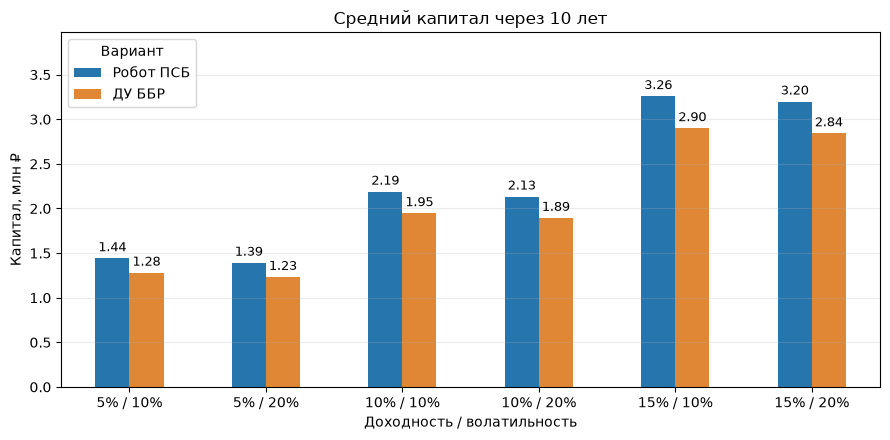

In [5]:
base = table[(table['Ребалансировка']=='Ежеквартально') & table['Зачет убытков']]
scenario_order = list(product([5, 10, 15], [10, 20]))
scenario_labels = [f'{r}% / {s}%' for r, s in scenario_order]
colors = {'Робот ПСБ': '#2676ad', 'ДУ ББР': '#df8734'}
capital = base.pivot(index=['Доходность, %', 'Волатильность, %'],
                     columns='Вариант', values='Капитал, ₽').reindex(scenario_order)[list(TARIFFS)]
ax = (capital/1e6).plot.bar(color=colors, rot=0, figsize=(9, 4.5))
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
ax.set_xticklabels(scenario_labels)
ax.set(xlabel='Доходность / волатильность', ylabel='Капитал, млн ₽',
       title='Средний капитал через 10 лет', ylim=(0, capital.max().max()/1e6*1.22))
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

### Из чего складываются расходы

Квартальная ребалансировка с зачетом убытков. Сумма частей столбца равна всем комиссиям и налогам за 10 лет.

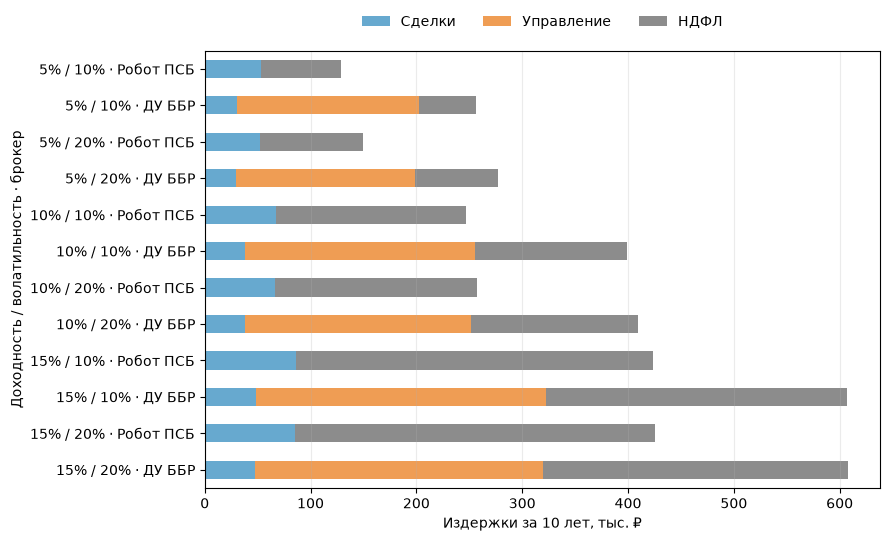

In [6]:
ordered = base.set_index(['Доходность, %', 'Волатильность, %', 'Вариант']).loc[
    [(r, s, name) for r, s in scenario_order for name in TARIFFS]]
expenses = ordered[['Сделки, ₽', 'Управление, ₽', 'НДФЛ, ₽']]/1000
expenses.columns = ['Сделки', 'Управление', 'НДФЛ']
expenses.index = [f'{r:g}% / {s:g}% · {name}' for r, s, name in ordered.index]
ax = expenses.plot.barh(stacked=True, color=['#67a9cf', '#ef9d54', '#8c8c8c'], figsize=(9, 5.5))
ax.invert_yaxis()
ax.set(xlabel='Издержки за 10 лет, тыс. ₽', ylabel='Доходность / волатильность · брокер')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.11), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

### Разброс результатов

Точка показывает медиану, отрезок от P10 до P90 охватывает 80% результатов. Пунктир отмечает начальный капитал 1 млн ₽.

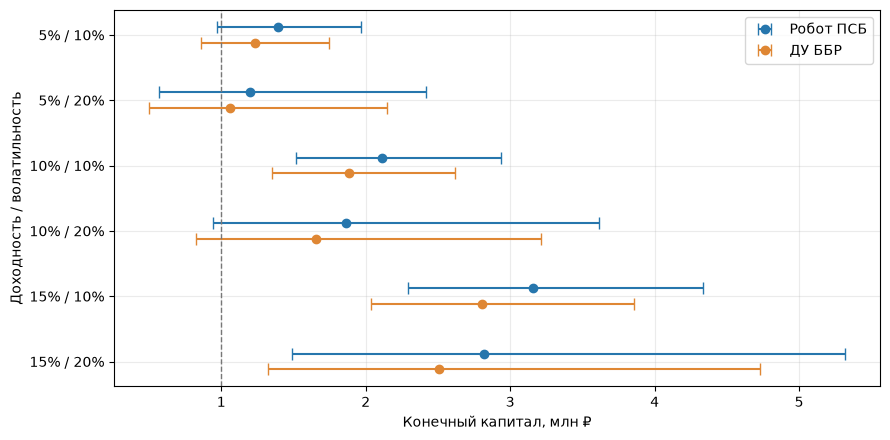

In [7]:
fig,ax = plt.subplots(figsize=(9,4.5))
y = np.arange(6)
for j,name in enumerate(TARIFFS):
    a = base[base['Вариант']==name].set_index(['Доходность, %','Волатильность, %']).loc[scenario_order]
    median = a['Медиана, ₽'].to_numpy()/1e6
    errors = np.vstack([median-a['P10, ₽'].to_numpy()/1e6,
                        a['P90, ₽'].to_numpy()/1e6-median])
    ax.errorbar(median,y+(j-.5)*.24,xerr=errors,fmt='o',capsize=4,
                label=name,color=colors[name])
ax.axvline(1,color='#777777',ls='--',lw=1)
ax.set_yticks(y,scenario_labels); ax.invert_yaxis()
ax.set(xlabel='Конечный капитал, млн ₽',ylabel='Доходность / волатильность')
ax.legend(); plt.tight_layout(); plt.show()

## 7. Точка безубыточности

Нахожу первый конец года, когда средний капитал робота выше и остается выше до конца расчета. Точность ответа один год. Промежуточный капитал учитывает уже уплаченные налоги, но не налог при возможной продаже всех бумаг. На десятой дате портфель полностью закрыт.

In [8]:
base_comparison = comparison[
    (comparison['Ребалансировка'] == 'Ежеквартально') & comparison['Зачет убытков']
]
summary = base_comparison[['Доходность, %', 'Волатильность, %',
                          'Преимущество робота, ₽', 'Преимущество / ДУ, %',
                          'Первый устойчивый год']].copy()
summary.columns = ['Доход, %', 'Риск, %', 'Выгода, ₽', 'Выгода, %', 'Год']
display(summary.reset_index(drop=True).round(2))

,"Доход, %","Риск, %","Выгода, ₽","Выгода, %",Год
0,5.00,10.00,"161,749.40",12.65,1
1,5.00,20.00,"158,894.97",12.91,1
2,10.00,10.00,"241,582.10",12.42,1
3,10.00,20.00,"239,374.37",12.65,1
4,15.00,10.00,"359,677.69",12.41,1
5,15.00,20.00,"355,841.31",12.53,1


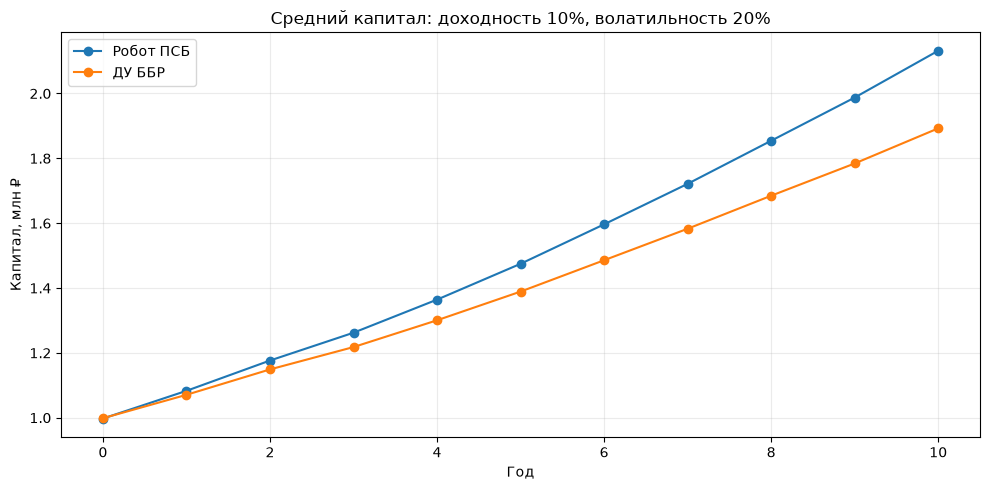

In [9]:
fig,ax=plt.subplots()
for name in TARIFFS:
    x=results[(.10,.20,3,True,name)]
    ax.plot(np.arange(11),np.r_[x['initial_nav'].mean(),x['yearly'].mean(axis=1)]/1e6,'o-',label=name)
ax.set(title='Средний капитал: доходность 10%, волатильность 20%',xlabel='Год',ylabel='Капитал, млн ₽')
ax.legend(); plt.tight_layout(); plt.show()

## 8. Анализ чувствительности

Меняю частоту ребалансировки и зачет убытков. Доля продажи всегда 20%. Налоговый режим меняется одновременно для робота и ДУ.

На графике показано преимущество робота по среднему конечному капиталу, в тыс. ₽. Цветовая шкала одинаковая для двух налоговых режимов.

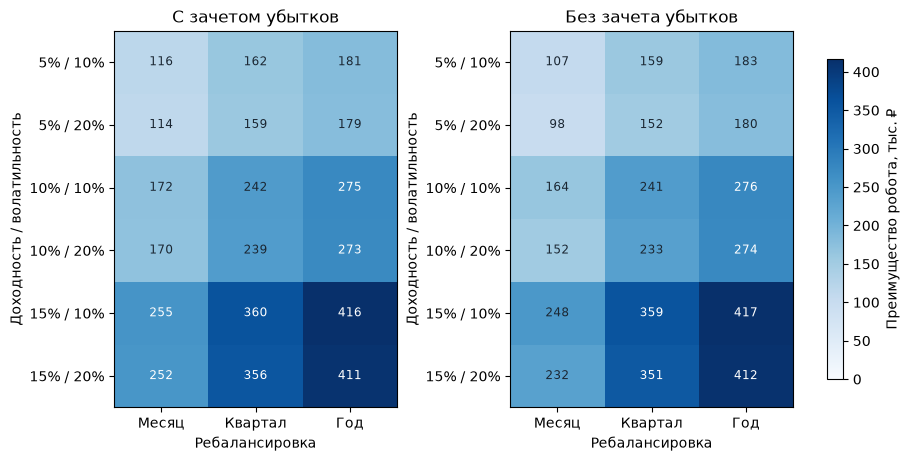

In [10]:
def scenario_grid(frame, metric, netting, columns):
    return frame[frame['Зачет убытков']==netting].pivot(
        index=['Доходность, %', 'Волатильность, %'],
        columns=columns, values=metric).reindex(scenario_order)


def heatmap(ax, values, labels, title, cmap, limits, fmt=',.0f', suffix=''):
    lower, upper = limits
    im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap,
                   vmin=lower, vmax=upper, aspect='auto')
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(scenario_labels)), scenario_labels)
    ax.set(title=title, ylabel='Доходность / волатильность')
    ax.grid(False)
    for (row, col), value in np.ndenumerate(values):
        label = (format(value, fmt).replace(',', ' ') + suffix) if np.isfinite(value) else 'нет'
        shade = (value-lower)/(upper-lower) if upper > lower else 0
        ax.text(col, row, label, ha='center', va='center', fontsize=8.5,
                color='white' if shade > .6 else '#1b2733')
    return im


modes = {True: 'С зачетом убытков', False: 'Без зачета убытков'}
period_labels = ['Месяц', 'Квартал', 'Год']
grids = [scenario_grid(comparison, 'Преимущество робота, ₽', flag, 'Ребалансировка')
         [list(frequency.values())].to_numpy()/1000 for flag in modes]
limits = min(0, np.min(grids)), np.max(grids)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), layout='constrained')
for ax, values, title in zip(axes, grids, modes.values()):
    im = heatmap(ax, values, period_labels, title, 'Blues', limits)
    ax.set_xlabel('Ребалансировка')
fig.colorbar(im, ax=axes, label='Преимущество робота, тыс. ₽', shrink=.85)
plt.show()

## 9. Пояснительная записка

Сравнил робота ПСБ, тариф «Инвестор», и ДУ ББР «Облигационная»
со сделками по тарифу «Успешный инвестор». Дата тарифов **29.10.2026**.
Источники: [ПСБ](https://www.psbank.ru/personal/wealth/rates),
[ДУ ББР](https://bbrbroker.ru/products/doveritelnoe-upravlenie/),
[тариф ББР](https://bbrbroker.ru/upload/iblock/911/4yrntyuw46ysu8b828rpy2w268tac7w0.pdf).
У робота управление бесплатное, у ДУ стоит 1,5% годовых.

При доходности 10%, волатильности 20% и квартальной ребалансировке средний капитал
через 10 лет составил **2 131 864 ₽** у робота и **1 892 490 ₽** у ДУ.
Преимущество робота **239 374 ₽**, на годовых датах оно сохраняется с **1-го года**.
Издержки составили 257 643 ₽ и 409 693 ₽,
или 12.09% и 21.65% конечного капитала.

При месячной, квартальной и ежегодной ребалансировке преимущество робота равно
170 490, 239 374 и 272 710 ₽.
Частые сделки уменьшают его выгоду, потому что комиссия ПСБ выше.
Зачет убытков добавил к капиталу робота 54 082 ₽, а ДУ 47 765 ₽.

Вывод совпадает с идеей из лекции 7: экономия на ежегодной плате заметна на длинном сроке.
Но это результат при одинаковой валовой доходности. Дополнительную доходность от работы
управляющего я не закладывал. Расчет зависит от принятых допущений: тариф исполнения сделок ДУ,
постоянные комиссии и доход корзины без отдельных купонов.

## 10. Все сценарии на графиках

Каждая клетка показывает результат одного варианта. Строки задают доходность и волатильность, столбцы задают частоту ребалансировки и способ управления. Значения капитала и расходов подписаны в рублях, доля расходов в процентах. Результаты усреднены по 3 000 траекториям. Для двух налоговых режимов использую одинаковую шкалу цвета.

In [11]:
chart_columns = list(product(frequency.values(), TARIFFS))
chart_labels = [f'{period}\n{name}' for period, name in product(period_labels, ['ПСБ', 'ББР'])]


def scenario_chart(metric, netting, title, cmap):
    values = scenario_grid(table, metric, netting, ['Ребалансировка', 'Вариант'])
    fig, ax = plt.subplots(figsize=(9.5, 4.7), layout='constrained')
    heatmap(ax, values[chart_columns].to_numpy(), chart_labels,
            f'{title}: {modes[netting].lower()}', cmap,
            (table[metric].min(), table[metric].max()), '.2f' if '%' in metric else ',.0f')
    for boundary in [1.5, 3.5]:
        ax.axvline(boundary, color='white', lw=2)
    plt.show()

### Конечный капитал, ₽

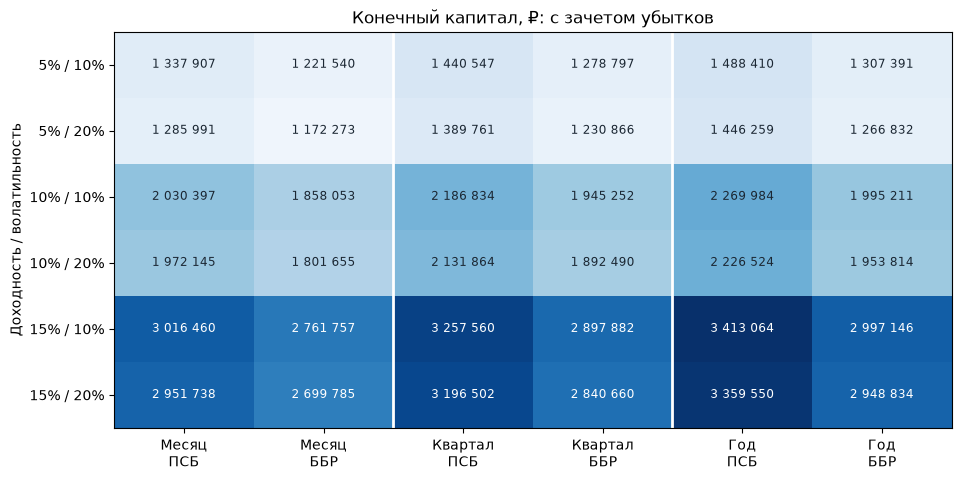

In [12]:
scenario_chart('Капитал, ₽', True, 'Конечный капитал, ₽', 'Blues')

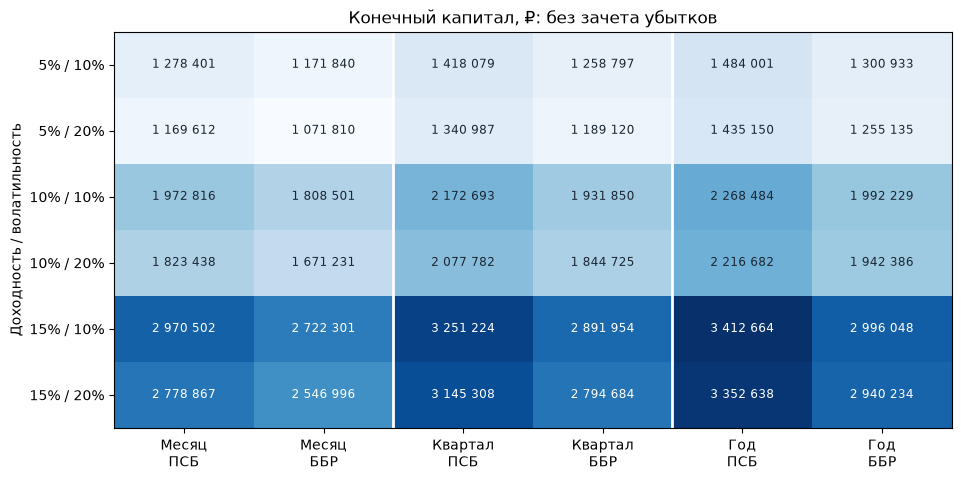

In [13]:
scenario_chart('Капитал, ₽', False, 'Конечный капитал, ₽', 'Blues')

### Комиссии и налоги, ₽

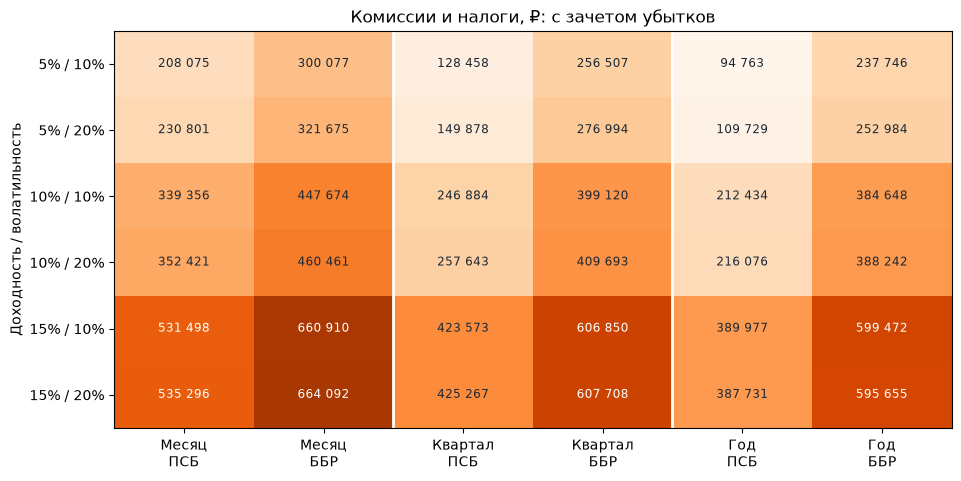

In [14]:
scenario_chart('Издержки, ₽', True, 'Комиссии и налоги, ₽', 'Oranges')

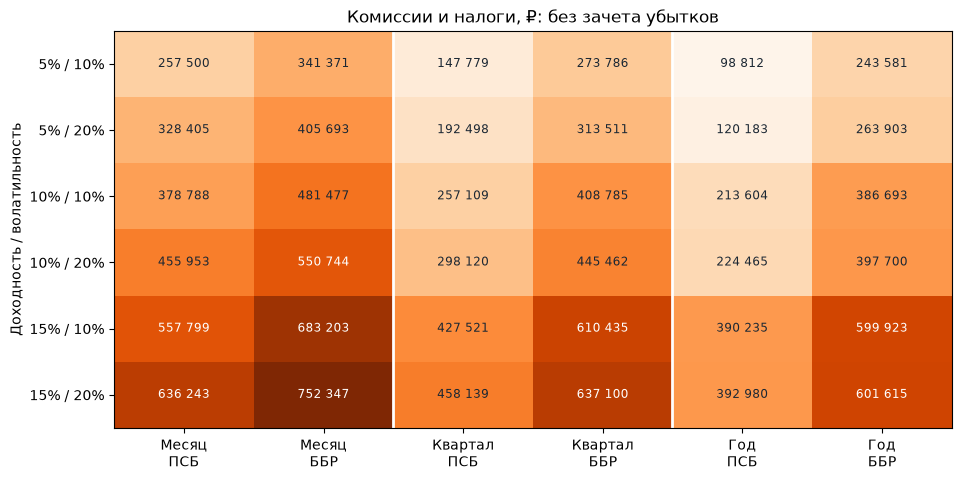

In [15]:
scenario_chart('Издержки, ₽', False, 'Комиссии и налоги, ₽', 'Oranges')

### Издержки от конечного капитала, %

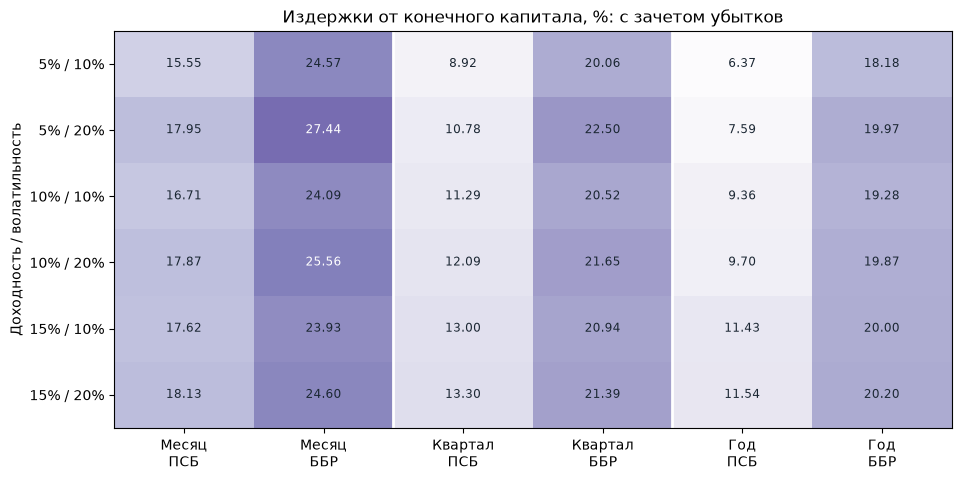

In [16]:
scenario_chart('Издержки / капитал, %', True, 'Издержки от конечного капитала, %', 'Purples')

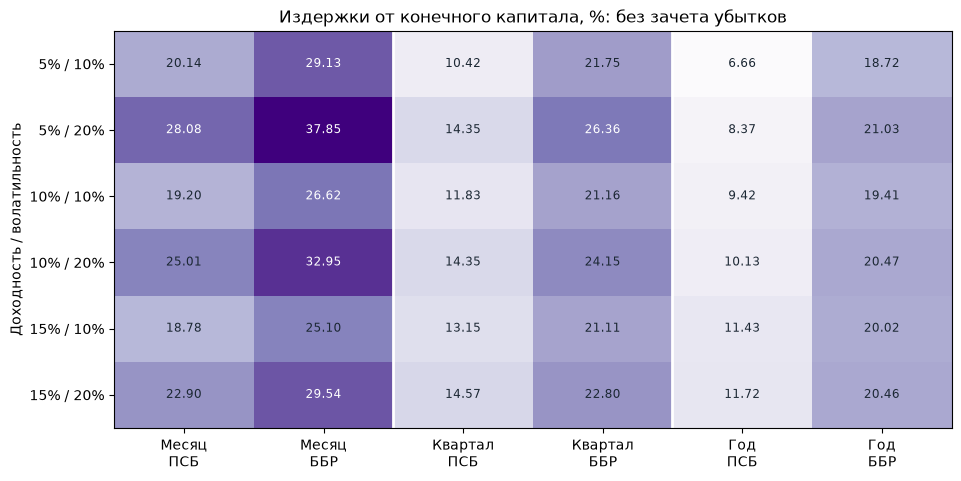

In [17]:
scenario_chart('Издержки / капитал, %', False, 'Издержки от конечного капитала, %', 'Purples')

### Год, с которого робот выходит вперед

В клетке указан номер года, а не доходность и не вероятность. «1-й» означает, что робот уже впереди к концу первого года и сохраняет преимущество на следующих годовых датах. Это не значит, что варианты сравнялись ровно через год: внутри года точку пересечения не ищу. Если преимущества нет за 10 лет, в клетке будет «нет».

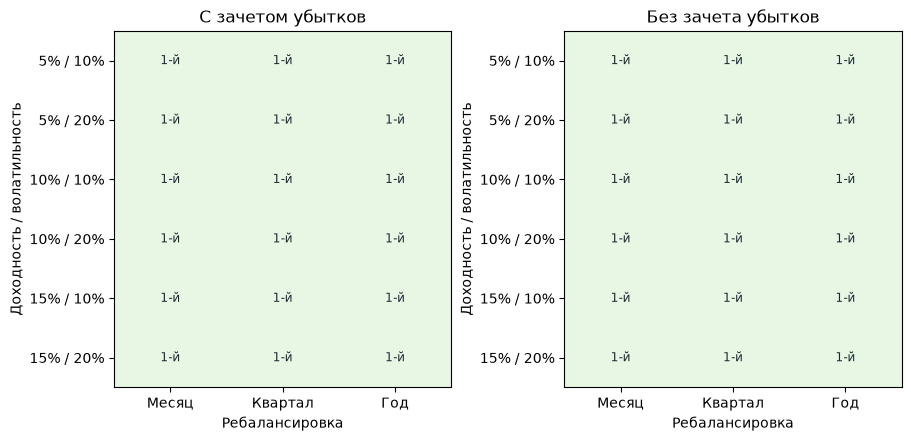

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), layout='constrained')
for ax, flag in zip(axes, modes):
    values = scenario_grid(comparison, 'Первый устойчивый год', flag, 'Ребалансировка')
    heatmap(ax, values[list(frequency.values())].to_numpy(dtype=float), period_labels,
            modes[flag], 'Greens', (0, YEARS), '.0f', '-й')
    ax.set_xlabel('Ребалансировка')
plt.show()